# 04 - The trade-off map: is a mitigation better than just degrading the model?

Every bias-mitigation method trades some accuracy for some fairness. But is the trade *worth it*? **Fairea** (Hort et al., ESEC/FSE 2021) answers this in three steps:

1. **Baseline.** Train the original model, then overwrite a growing fraction (0%, 10%, ..., 100%) of its test predictions with one constant label. Accuracy and bias both fall: this is the price of fairness you would pay for free, with no mitigation.
2. **Normalise** accuracy and bias by the baseline's range, so the original model sits at (1, 1) and the fully mutated model at (0, 0).
3. **Classify** each mitigation by region (win-win, good / poor trade-off, lose-lose, inverted) and, for good trade-offs, measure the **area** gained over the baseline.

**Prerequisites:** notebooks 00, 01 and 03. **Runtime:** a few minutes. **Data:** stroke prediction, attribute `age` (65 or older = privileged).

Bias here is `|SPD|` (absolute statistical parity difference, 0 = fair), a single linear group metric, and accuracy is *balanced* accuracy. Both choices are explained below.

In [1]:
from fhg_examples import setup; setup()

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from callmefair import BMGridSearch, BMInterface, BMType
from fhg_examples.datasets import SPECS, load
from callmefair.tradeoff import baseline_curve, create_baseline, select_strategy, tradeoff_regions
from callmefair.viz import plot_tradeoff_map

spec = SPECS["stroke"]
privileged, unprivileged = spec.attribute("age").groups     # age 1 = 65 or older (reference)
df = load("stroke")
SPLIT = dict(test_size=0.2, val_size=0.2)   # same split settings for the baseline and the grid
print(f"{len(df):,} rows | stroke rate {df.stroke.mean():.3f} | older share {df.age.mean():.3f}")

5,109 rows | stroke rate 0.049 | older share 0.201


## 1. The baseline: degrade the model on purpose

`create_baseline` takes a *factory* (so each split gets a fresh model), trains it on `data_splits` random splits and mutates the test predictions `repetitions` times per degree, towards label 0 and towards label 1. Fairea uses 50 x 50; we use 10 x 10, which is enough for a stable curve here.

> **Caveat.** The age gap largely reflects clinical risk; base-rate differences are not by themselves unfair. With few positive cases results vary with the seed.

In [3]:
base = create_baseline(lambda: LogisticRegression(max_iter=1000), df, "stroke", "age",
                       privileged, unprivileged, data_splits=10, repetitions=10, seed=0,
                       bmi_kwargs=SPLIT)
strategy = select_strategy(base)
curve = baseline_curve(base)                    # balanced accuracy and |SPD| by default
print(f"chosen strategy: {strategy}")
curve.rename(columns={"accuracy": "balanced_acc", "bias": "|SPD|"}).round(3)

chosen strategy: to_1


,degree,balanced_acc,|SPD|
0,0.0,0.729,0.875
1,0.1,0.706,0.787
2,0.2,0.682,0.698
3,0.3,0.660,0.613
4,0.4,0.640,0.526
5,0.5,0.617,0.437
6,0.6,0.593,0.349
7,0.7,0.570,0.263
8,0.8,0.547,0.175
9,0.9,0.524,0.088


Fairea keeps the mutation label whose 100%-mutated model has the **highest accuracy** (ties go to the stricter curve), so the baseline is the hardest one to beat. The raw baseline below has the original model F_OM at the top right and the constant model F100 at the bottom left. With a linear bias metric it is close to a straight line.

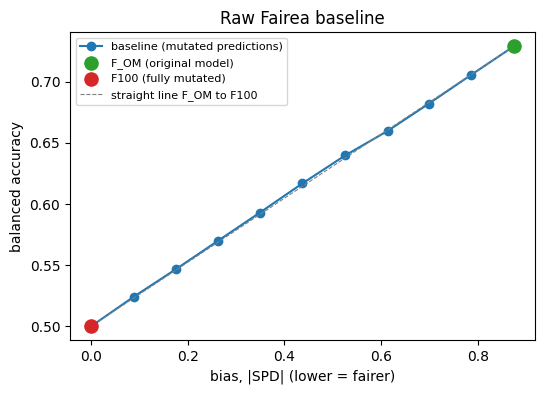

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(curve.bias, curve.accuracy, "o-", color="tab:blue", label="baseline (mutated predictions)")
ax.scatter(*curve[["bias", "accuracy"]].iloc[0], s=90, color="tab:green", zorder=3, label="F_OM (original model)")
ax.scatter(*curve[["bias", "accuracy"]].iloc[-1], s=90, color="tab:red", zorder=3, label="F100 (fully mutated)")
ax.plot(curve.bias.iloc[[0, -1]], curve.accuracy.iloc[[0, -1]], "--", color="gray", lw=0.8, label="straight line F_OM to F100")
ax.set(xlabel="bias, |SPD| (lower = fairer)", ylabel="balanced accuracy", title="Raw Fairea baseline")
ax.legend(fontsize=8); plt.show()

## 2. Why balanced accuracy? The plain-accuracy problem

Fairea requires the original model to beat the constant model. On imbalanced labels, plain accuracy breaks this: stroke is rare, so predicting "no stroke" for everyone is *more* accurate than the real model.

In [5]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    plain = baseline_curve(base, accuracy="acc")
print(f"acc at 0% mutation: {plain.accuracy.iloc[0]:.3f} | at 100%: {plain.accuracy.iloc[-1]:.3f}")
for w in caught:
    print("WARNING:", w.message)

acc at 0% mutation: 0.726 | at 100%: 0.951


Mutating towards the majority label *raises* plain accuracy, so "sacrificing accuracy for fairness" is meaningless and the regions would be invalid. Balanced accuracy ends at 0.5 for any constant model, so it is the default.

## 3. Method points: a grid search

We evaluate two models (logistic regression, XGBoost) with six mitigations: pre-, post-processing and two pre+post chains. `BMGridSearch` returns one row per combination, including the unmitigated model (`baseline`). One split is noisy, so we run three seeds; `tradeoff_regions` averages repeated (model, BM) rows.

In [6]:
SEEDS = range(3)
BM_LIST = [[BMType.preReweighing], [BMType.preDisparate], [BMType.posEqqOds], [BMType.posROC],
           [BMType.preReweighing, BMType.posROC], [BMType.preDisparate, BMType.posROC]]
MODELS = [LogisticRegression(max_iter=1000),
          XGBClassifier(n_estimators=100, max_depth=3, eval_metric="logloss", verbosity=0)]

rows = []
for seed in SEEDS:
    bm_i = BMInterface(df, label="stroke", protected=["age"], random_state=seed, **SPLIT)
    for model in MODELS:
        grid = BMGridSearch(bm_i, model, BM_LIST, privileged, unprivileged)
        rows += grid.run_single_sensitive(results_dir=None)
len(rows)

42

In [7]:
regions = tradeoff_regions(base, rows)        # balanced accuracy and |SPD|
table = (regions.assign(order=regions.region.map({r: i for i, r in enumerate(
             ["win-win", "good trade-off", "bad trade-off", "inverted", "lose-lose"])}))
         .sort_values(["order", "area"], ascending=[True, False])
         .rename(columns={"accuracy": "balanced_acc", "bias": "|SPD|"})
         [["model", "BM", "balanced_acc", "|SPD|", "paper_region", "area"]])
print(regions.region.value_counts().to_dict())
table.round(3).reset_index(drop=True)

{'good trade-off': 9, 'bad trade-off': 2, 'lose-lose': 1}


,model,BM,balanced_acc,|SPD|,paper_region,area
0,LogisticRegression,preReweighing posROC,0.606,0.043,Good,0.084
1,LogisticRegression,preReweighing,0.617,0.091,Good,0.080
2,LogisticRegression,preDisparate posROC,0.609,0.069,Good,0.077
3,LogisticRegression,posROC,0.609,0.082,Good,0.072
4,XGBClassifier,preDisparate posROC,0.580,0.040,Good,0.045
5,XGBClassifier,preReweighing,0.648,0.295,Good,0.045
6,XGBClassifier,posROC,0.571,0.026,Good,0.038
7,XGBClassifier,preReweighing posROC,0.564,0.046,Good,0.025
8,XGBClassifier,preDisparate,0.696,0.660,Good,0.006
9,LogisticRegression,posEqqOds,0.498,0.004,Poor,0.000


## 4. The map

How to read it: both axes are normalised by the baseline, so **F_OM (the original model) is at (1, 1)** and F100 at (0, 0). Lines through F_OM split the plane into regions (paper Fig. 2):

- **win-win**: at least as accurate and no more biased than the original;
- **inverted**: more accurate but more biased; **lose-lose**: less accurate and more biased;
- **good trade-off**: less accurate but fairer, and *above* the baseline (better than random degradation); **poor**: below it.

The diagonal-like curve is the baseline. For good trade-offs, the shaded **area** between the method and the baseline (paper Fig. 3) is its gain: larger is better.

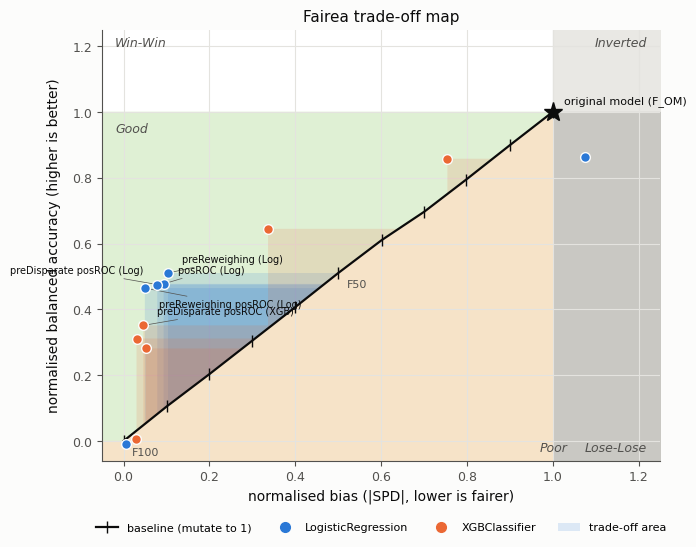

In [8]:
_ = plot_tradeoff_map(base, regions)
plt.show()

## 5. Optional: the composite fairness score

`bias="fair_score"` uses the composite score from notebook 01. Its baseline is *not* a straight line: the score jumps by 0.2 whenever a metric leaves its acceptable range and is capped at 1, so the curve bends and saturates. Fairea uses a single linear group metric, which is why `|SPD|` is the default. Treat this variant with caution; `"aod"` and `"eod"` are linear alternatives.

In [9]:
regions_f = tradeoff_regions(base, rows, bias="fair_score")
print(regions_f.region.value_counts().to_dict())
regions_f[["model", "BM", "paper_region", "area"]].round(3).sort_values("area", ascending=False).reset_index(drop=True)

{'good trade-off': 8, 'lose-lose': 2, 'bad trade-off': 2}


,model,BM,paper_region,area
0,LogisticRegression,posROC,Good,0.087
1,LogisticRegression,preReweighing,Good,0.085
2,LogisticRegression,preReweighing posROC,Good,0.069
3,LogisticRegression,preDisparate posROC,Good,0.067
4,XGBClassifier,posROC,Good,0.041
5,XGBClassifier,preDisparate posROC,Good,0.040
6,XGBClassifier,preReweighing posROC,Good,0.033
7,XGBClassifier,preReweighing,Good,0.019
8,LogisticRegression,preDisparate,Lose-Lose,0.000
9,LogisticRegression,posEqqOds,Poor,0.000


In [10]:
from IPython.display import Markdown, display
good = regions[regions.region == "good trade-off"]
verdict = (f"{len(good)} of {len(regions)} mitigation results are **good trade-offs** (" + ", ".join(good.model + " " + good.BM) + ")"
           if len(good) else "**no mitigation is a good trade-off**: none beats degrading the model")
display(Markdown(f"**Is a mitigation better than just degrading the model?** On this run, for `age`: {verdict}."))

**Is a mitigation better than just degrading the model?** On this run, for `age`: 9 of 12 mitigation results are **good trade-offs** (LogisticRegression preReweighing, LogisticRegression posROC, LogisticRegression preReweighing posROC, LogisticRegression preDisparate posROC, XGBClassifier preReweighing, XGBClassifier preDisparate, XGBClassifier posROC, XGBClassifier preReweighing posROC, XGBClassifier preDisparate posROC).

## Summary

- The **baseline** (mutating the original model's predictions) is the free-lunch yardstick; any mitigation must beat it.
- Axes are normalised by the baseline's range: F_OM = (1, 1), F100 = (0, 0). Use balanced accuracy on imbalanced labels and a linear bias metric (`|SPD|`).
- `tradeoff_regions` returns each method's region and, for good trade-offs, the area over the baseline; `plot_tradeoff_map` draws it.
- Only good trade-offs have an area; win-win is a free gain; lose-lose and inverted are not worth using; poor trade-offs lose to random degradation.
- Results are noisy with few positives: treat points near the baseline as ties and average over seeds.
- `results_dir=None` keeps `BMGridSearch` from writing CSVs.

**Next:** [05_advanced_models_and_hardware.ipynb](05_advanced_models_and_hardware.ipynb) shows other model families, custom models, GPU settings and intersectional attributes.